In [62]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [59]:
test = pd.read_csv('sign_mnist_test.csv')
train = pd.read_csv('sign_mnist_train.csv')

In [60]:
train.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [33]:
test.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


In [34]:
x_train = train.drop('label',axis=1).values
y_train = train["label"].values

In [35]:
x_test = test.drop('label',axis=1).values
y_test = test['label'].values

In [36]:
x_train = x_train/255.0
x_test = x_test/255.0

In [37]:
x_train = x_train.reshape(-1,784)
x_test = x_test.reshape(-1,784)

In [38]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128,activation='relu'),
    layers.Dense(64,activation = 'relu'),
    layers.Dense(25,activation= 'softmax')
])

In [39]:
model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [40]:
history = model.fit(
    x_train,y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (x_test,y_test)
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 760us/step - accuracy: 0.3210 - loss: 2.1866 - val_accuracy: 0.4777 - val_loss: 1.6817
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 792us/step - accuracy: 0.5902 - loss: 1.2736 - val_accuracy: 0.5371 - val_loss: 1.4426
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 711us/step - accuracy: 0.6978 - loss: 0.9277 - val_accuracy: 0.6089 - val_loss: 1.2367
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - accuracy: 0.7742 - loss: 0.7072 - val_accuracy: 0.6156 - val_loss: 1.1968
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 671us/step - accuracy: 0.8283 - loss: 0.5455 - val_accuracy: 0.6588 - val_loss: 1.1236
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 676us/step - accuracy: 0.8725 - loss: 0.4123 - val_accuracy: 0.6647 - val_loss: 1.1807
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 624us/step - accuracy: 0.9056 - loss: 0.3161 - val_accuracy: 0.6704 - val_loss: 1.1215
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 1s 802us/step - accuracy: 0.9275 - loss: 0.2446 - 

In [41]:
loss, accuracy = model.evaluate(x_test,y_test)
print("Training accuracry = ", history.history['accuracy'][-1] * 100)
print("Testing accuracy =" , accuracy *100)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step - accuracy: 0.6990 - loss: 1.1941
Training accuracry =  96.16098999977112
Testing accuracy = 69.8968231678009


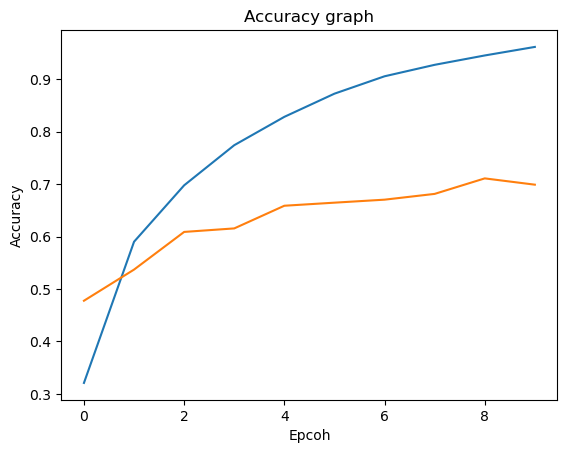

In [45]:
plt.plot(history.history['accuracy'], label="training loss")
plt.plot(history.history['val_accuracy'], label="testing loss")

plt.title("Accuracy graph")
plt.xlabel("Epcoh")
plt.ylabel("Accuracy")
plt.show()

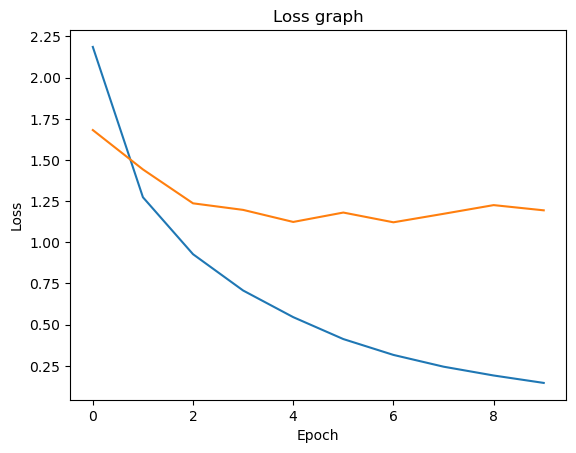

In [47]:
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label="testing loss")

plt.title('Loss graph')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.show()

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 250us/step


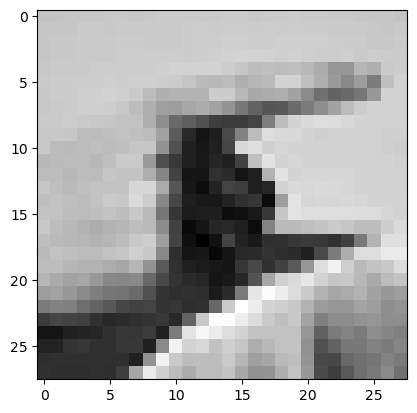

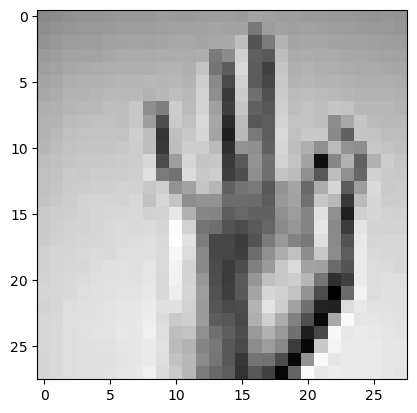

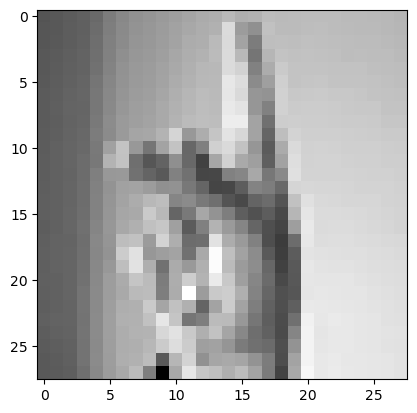

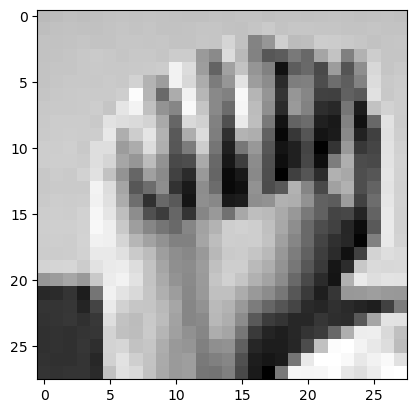

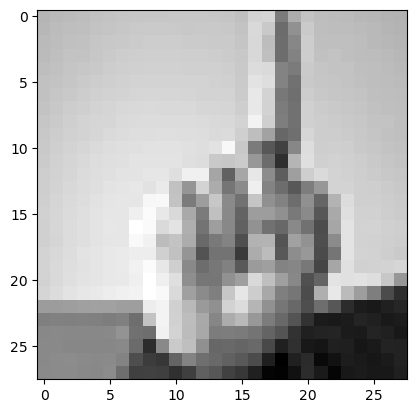

In [55]:
predictions = model.predict(x_test)
predicted_labels = np.argmax(predictions, axis=1)

for i in range(5):
    plt.imshow(x_test[i].reshape(28,28),cmap='gray')
    plt.show()

In [56]:
for i in range(5):
    print("Actual = ",y_test[i],
            "prediction = ",predicted_labels[i])
          

Actual =  6 prediction =  6
Actual =  5 prediction =  5
Actual =  10 prediction =  10
Actual =  0 prediction =  0
Actual =  3 prediction =  3


Text(95.72222222222221, 0.5, 'Actual Labels')

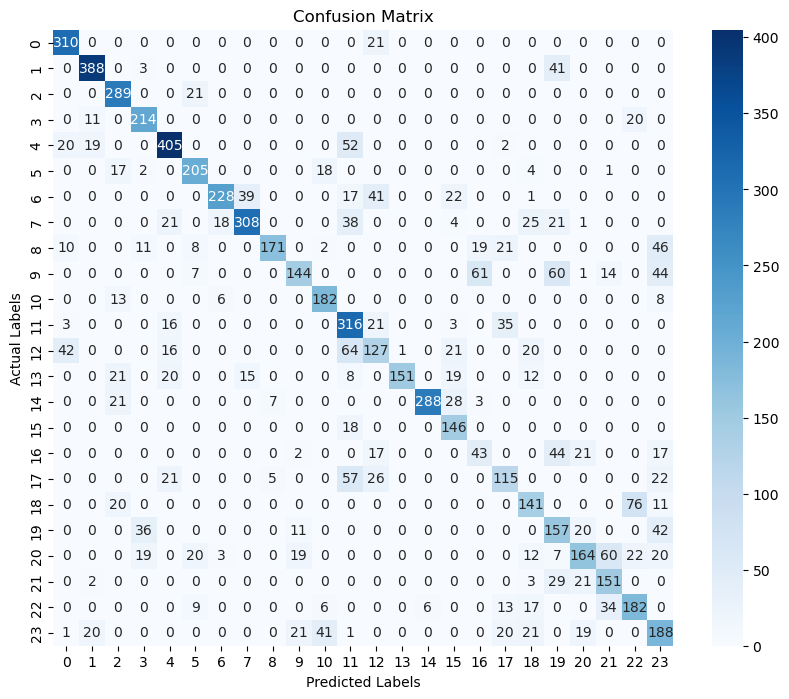

In [63]:
cm = confusion_matrix(y_test, predicted_labels)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")